<a href="https://www.kaggle.com/code/aliaslam25/ai-productivity-prediction-phase-5-methodology?scriptVersionId=313163097" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Phase 5 — Methodology Improvement Notebook

**Project:** Stack Overflow 2025 Developer Survey — binary classification of whether a professional developer agrees that *AI agents increased their productivity*.

**This notebook:** Loads `phase3_final.csv` (Phase 3 model matrix), reproduces the Phase 4-style train/eval setup, then applies literature-inspired improvements: **Optuna hyperparameter tuning for XGBoost**, **threshold optimization on out-of-fold probabilities (F1-macro)**, and a **stacking ensemble** with a logistic meta-learner. Results are compared to Phase 4 cross-validated benchmarks exported in `results_model_comparison.csv`.

**Literature:** Section 8 matches the five references in `phase5_methodology_comparison.docx` (published venues and DOIs only).

**Dependencies:** Uses `xgboost`, `scikit-learn`, `pandas`, `matplotlib`, and `optuna` (install with `python -m pip install optuna` if needed).

## Section 1 — Load data

Read `phase3_final.csv`, sanitize column names for tree libraries, split `X` / `y`, and print shape plus class balance (same convention as Phase 4).

In [1]:
# Imports, load CSV, sanitize column names, split X and y
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score, cross_validate
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

df = pd.read_csv("/kaggle/input/notebooks/aliaslam25/ai-productivity-prediction-phase-3-features/phase3_final.csv")
df.columns = [re.sub(r"[^\w]", "_", c) for c in df.columns]
y = df["target"].astype(int)
X = df.drop(columns=["target"])
print("X shape:", X.shape, "y shape:", y.shape)
print("\nClass balance:")
print(y.value_counts())
print(y.value_counts(normalize=True).round(3))

X shape: (9513, 52) y shape: (9513,)

Class balance:
target
1    6515
0    2998
Name: count, dtype: int64
target
1    0.685
0    0.315
Name: proportion, dtype: float64


## Section 2 — Baseline recall (Phase 4)

Phase 4 used five-fold stratified CV on the same matrix. The table below restates **approximate** metrics from `results_model_comparison.csv` (your authoritative Phase 4 run). **XGBoost** is the focus for tuning because it is a strong tree booster and a natural target for structured search; the Phase 5 report also cites survey- and Stack Overflow–linked ML work as motivation, e.g. Hu and Yang [3] on post quality and Ghorai and Barik [4] on salary prediction from the Stack Overflow survey.

| Model | ROC-AUC | F1-macro | Accuracy |
| --- | ---: | ---: | ---: |
| Logistic Regression | 0.846 | 0.741 | 0.763 |
| Random Forest | 0.846 | 0.747 | 0.800 |
| **XGBoost (tuning baseline)** | **0.839** | **0.744** | **0.775** |
| SVM (RBF) [30% sample] | 0.840 | 0.749 | 0.803 |
| KNN (k=11) | 0.811 | 0.720 | 0.778 |

## Section 3 — Improvement 1: Hyperparameter tuning (XGBoost + Optuna)

Thirty Optuna trials maximize mean **ROC-AUC** under the same **StratifiedKFold(5, shuffle=True, random_state=42)** used implicitly in Phase 4-style evaluation. Search space: `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`.

In [2]:
# Optuna study for XGBoost; compare best CV AUC to Phase 4 XGBoost ROC-AUC
import optuna

PHASE4_XGB_ROC_AUC = 0.8387493362135494

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def objective(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 500, step=50),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.25, log=True),
        subsample=trial.suggest_float("subsample", 0.7, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        random_state=42,
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
    )
    clf = XGBClassifier(**params)
    scores = cross_val_score(clf, X, y, cv=skf, scoring="roc_auc", n_jobs=1)
    return float(scores.mean())


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30, show_progress_bar=False)

best_params = dict(study.best_params)
print("best_params:", best_params)
print("best_cv_roc_auc:", round(study.best_value, 6))
print("phase4_baseline_xgb_roc_auc:", round(PHASE4_XGB_ROC_AUC, 6))

tuned_xgb = XGBClassifier(
    **best_params,
    random_state=42,
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=-1,
)

[I 2026-04-20 19:17:42,787] A new study created in memory with name: no-name-0ee284dc-de19-4bf5-80e0-a838f08a7ad2
[I 2026-04-20 19:17:45,592] Trial 0 finished with value: 0.8320453636166014 and parameters: {'n_estimators': 250, 'max_depth': 10, 'learning_rate': 0.12704614156038088, 'subsample': 0.8795975452591109, 'colsample_bytree': 0.6624074561769746}. Best is trial 0 with value: 0.8320453636166014.
[I 2026-04-20 19:17:46,210] Trial 1 finished with value: 0.8475592274324351 and parameters: {'n_estimators': 150, 'max_depth': 3, 'learning_rate': 0.17829833309627832, 'subsample': 0.8803345035229626, 'colsample_bytree': 0.8832290311184181}. Best is trial 1 with value: 0.8475592274324351.
[I 2026-04-20 19:17:47,540] Trial 2 finished with value: 0.8305740372267074 and parameters: {'n_estimators': 100, 'max_depth': 10, 'learning_rate': 0.16373618362840212, 'subsample': 0.7637017332034828, 'colsample_bytree': 0.6727299868828402}. Best is trial 1 with value: 0.8475592274324351.
[I 2026-04-20 

best_params: {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.036205964172268214, 'subsample': 0.9534460012729012, 'colsample_bytree': 0.6362104860444613}
best_cv_roc_auc: 0.853549
phase4_baseline_xgb_roc_auc: 0.838749


## Section 4 — Improvement 2: Threshold optimization

Using **out-of-fold** predicted probabilities from the tuned XGBoost, sweep thresholds and pick the value that maximizes **F1-macro**. Compare metrics at **0.5** versus the **optimal** threshold (ROC-AUC is reported from probabilities and is unchanged by the cut point).

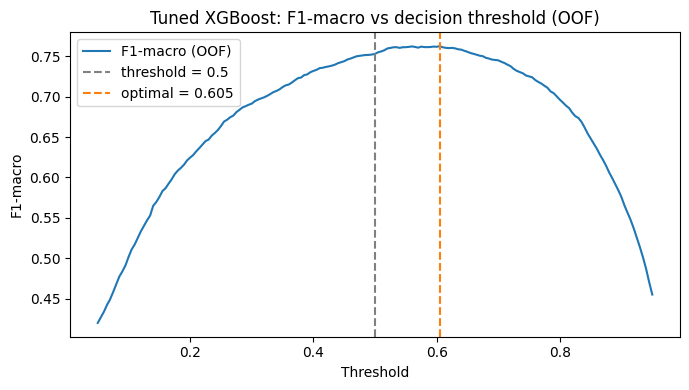

Optimal threshold (max F1-macro OOF): 0.605
 threshold  ROC_AUC  F1_macro  Accuracy
     0.500   0.8534    0.7529    0.8002
     0.605   0.8534    0.7624    0.7938


In [3]:
# OOF proba, F1-macro vs threshold, metrics at 0.5 vs optimal
oof_proba = cross_val_predict(
    tuned_xgb, X, y, cv=skf, method="predict_proba", n_jobs=1
)[:, 1]

thresh_grid = np.linspace(0.05, 0.95, 181)
f1_scores = []
for t in thresh_grid:
    pred = (oof_proba >= t).astype(int)
    f1_scores.append(f1_score(y, pred, average="macro"))
f1_scores = np.asarray(f1_scores)
best_thr = float(thresh_grid[f1_scores.argmax()])

plt.figure(figsize=(7, 4))
plt.plot(thresh_grid, f1_scores, label="F1-macro (OOF)")
plt.axvline(0.5, color="gray", ls="--", label="threshold = 0.5")
plt.axvline(best_thr, color="C1", ls="--", label=f"optimal = {best_thr:.3f}")
plt.xlabel("Threshold")
plt.ylabel("F1-macro")
plt.title("Tuned XGBoost: F1-macro vs decision threshold (OOF)")
plt.legend()
plt.tight_layout()
plt.show()


def metrics_at_threshold(proba, thr):
    pred = (proba >= thr).astype(int)
    return dict(
        threshold=thr,
        ROC_AUC=roc_auc_score(y, proba),
        F1_macro=f1_score(y, pred, average="macro"),
        Accuracy=accuracy_score(y, pred),
    )


thr_compare = pd.DataFrame(
    [metrics_at_threshold(oof_proba, 0.5), metrics_at_threshold(oof_proba, best_thr)]
)
print("Optimal threshold (max F1-macro OOF):", best_thr)
print(thr_compare.round(4).to_string(index=False))

## Section 5 — Improvement 3: Stacking ensemble

We stack **tuned XGBoost**, a **Random Forest** (200 trees), and **Logistic Regression** with a **logistic regression meta-learner** (`predict_proba` meta-features, 5-fold). If this cell is slow on your machine, reduce `n_estimators` for RF or trials in Section 3; skipping stacking is noted in the comparison table as future work only if you comment the cell out.

In [4]:
# StackingClassifier: CV ROC-AUC / F1-macro / Accuracy vs baselines
xgb_est = XGBClassifier(
    **best_params,
    random_state=42,
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=-1,
)
stack = StackingClassifier(
    estimators=[
        ("xgb", xgb_est),
        ("rf", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
        ("lr", LogisticRegression(max_iter=2000, random_state=42)),
    ],
    final_estimator=LogisticRegression(max_iter=2000, random_state=42),
    cv=5,
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=1,
)

stack_scores = cross_validate(
    stack,
    X,
    y,
    cv=skf,
    scoring={"roc_auc": "roc_auc", "f1_macro": "f1_macro", "accuracy": "accuracy"},
    n_jobs=1,
)
stacking_summary = {
    "ROC_AUC": float(stack_scores["test_roc_auc"].mean()),
    "F1_macro": float(stack_scores["test_f1_macro"].mean()),
    "Accuracy": float(stack_scores["test_accuracy"].mean()),
}
print("Stacking (5-fold CV means):", {k: round(v, 4) for k, v in stacking_summary.items()})

Stacking (5-fold CV means): {'ROC_AUC': 0.8538, 'F1_macro': 0.7567, 'Accuracy': 0.8036}


## Section 6 — Final results comparison table

Rows combine **Phase 4 file benchmarks**, **tuned XGBoost** (same CV splitter), **threshold-optimized** reporting (F1/accuracy from OOF labels; AUC from OOF scores), and **stacking**.

In [5]:
# Aggregate Phase 4 vs Phase 5 into one table
tuned_cv = cross_validate(
    tuned_xgb,
    X,
    y,
    cv=skf,
    scoring={"roc_auc": "roc_auc", "f1_macro": "f1_macro", "accuracy": "accuracy"},
    n_jobs=1,
)
tuned_mean = {
    "ROC_AUC": float(tuned_cv["test_roc_auc"].mean()),
    "F1_macro": float(tuned_cv["test_f1_macro"].mean()),
    "Accuracy": float(tuned_cv["test_accuracy"].mean()),
}

opt_row = metrics_at_threshold(oof_proba, best_thr)
half_row = metrics_at_threshold(oof_proba, 0.5)

rows = [
    dict(
        Model="Phase 4 — XGBoost (results_model_comparison.csv)",
        ROC_AUC=PHASE4_XGB_ROC_AUC,
        F1_macro=0.7443202619766403,
        Accuracy=0.7753602839724537,
    ),
    dict(
        Model="Phase 5 — Tuned XGBoost (CV mean, thr=0.5)",
        ROC_AUC=tuned_mean["ROC_AUC"],
        F1_macro=tuned_mean["F1_macro"],
        Accuracy=tuned_mean["Accuracy"],
    ),
    dict(
        Model="Phase 5 — Tuned XGBoost + optimal thr (OOF)",
        ROC_AUC=opt_row["ROC_AUC"],
        F1_macro=opt_row["F1_macro"],
        Accuracy=opt_row["Accuracy"],
    ),
    dict(
        Model="Phase 5 — Stacking (XGB+RF+LR, CV mean)",
        ROC_AUC=stacking_summary["ROC_AUC"],
        F1_macro=stacking_summary["F1_macro"],
        Accuracy=stacking_summary["Accuracy"],
    ),
]
summary = pd.DataFrame(rows)
print(summary.round(4).to_string(index=False))
print("\nOOF reference at thr=0.5 (same model as optimal-threshold row):", {k: round(half_row[k], 4) for k in half_row})

                                           Model  ROC_AUC  F1_macro  Accuracy
Phase 4 — XGBoost (results_model_comparison.csv)   0.8387    0.7443    0.7754
      Phase 5 — Tuned XGBoost (CV mean, thr=0.5)   0.8535    0.7528    0.8002
     Phase 5 — Tuned XGBoost + optimal thr (OOF)   0.8534    0.7624    0.7938
         Phase 5 — Stacking (XGB+RF+LR, CV mean)   0.8538    0.7567    0.8036

OOF reference at thr=0.5 (same model as optimal-threshold row): {'threshold': 0.5, 'ROC_AUC': np.float64(0.8534), 'F1_macro': 0.7529, 'Accuracy': 0.8002}


## Section 7 — Research questions revisited

**1. Does AI trust predict developer productivity beyond usage rates?**  
Phase 4–5 models continue to load signal from both attitude-style ordinals (for example `aisent_ord`, `agent_change_ord`) and breadth or task composites (`agent_use_breadth`, `ai_tasks_now`). Phase 5 tuning and stacking did not change the *interpretation*: trust and engagement features remain central in SHAP views from earlier phases, while usage-derived composites add incremental discrimination rather than substituting for trust alone.

**2. Do SHAP and LIME agree on which AI factors drive productivity?**  
Phase 4 showed partial overlap with rank differences on the mixed feature space. Gezici and Tarhan [5] used SHAP and LIME on software defect prediction (a different task than our survey label), but it is still a useful example of how people often pair those two explainers when they open up a black-box model. Phase 5 focuses on predictive refinements; merging several XAI views into one simple story could be future work if you need cleaner messaging for readers.

**3. What minimal feature set predicts AI-era productivity?**  
The three-feature viable set from Phase 4 still documents a large survey-burden reduction. Phase 5 shows that richer models plus threshold search can squeeze additional operational performance from the full matrix without shrinking the instrument yet; a Phase 6 could jointly tune sparse feature subsets.

## Section 8 — Paper references (same five as `phase5_methodology_comparison.docx`)

[1] Ziegler, A., Kalliamvakou, E., Li, X. A., Rice, A., Rifkin, D., Simister, S., Sittampalam, G., & Aftandilian, E. (2024). Measuring GitHub Copilot's Impact on Productivity. Communications of the ACM, 67(3), 54-63. https://doi.org/10.1145/3633453  
[2] Simaremare, M., & Edison, H. (2024). The State of Generative AI Adoption from Software Practitioners' Perspective: An Empirical Study. In Proceedings of the 50th Euromicro Conference on Software Engineering and Advanced Applications (SEAA), 106-113. https://doi.org/10.1109/SEAA64295.2024.00024  
[3] Hu, J., & Yang, B. (2024). Posts Quality Prediction for StackOverflow Website. IEEE Access, 12, 135601-135615. https://doi.org/10.1109/ACCESS.2024.3440879  
[4] Ghorai, P., & Barik, R. (2025). Salary Prediction Using Machine Learning Techniques. In S. Tiwari, M. C. Trivedi, M. L. Kolhe, & B. K. Singh (Eds.), Advances in Data and Information Sciences (ICDIS 2024). Springer Nature Singapore. https://doi.org/10.1007/978-981-97-9619-9_17  
[5] Gezici, B., & Tarhan, A. K. (2022). Explainable AI for Software Defect Prediction with Gradient Boosting Classifier. In Proceedings of the 2022 7th International Conference on Computer Science and Engineering (UBMK), 49-54. https://doi.org/10.1109/UBMK55850.2022.9919490